# 09 — Regression Model Comparison

## Purpose
This notebook compares the regression models from the ML practical course using consistent evaluation rules.

**Target:** `price_etb`  
**Dataset:** `Practical_Dataset for ML.xlsx`, worksheet `Data`  
**Split:** 80% train / 20% test, `random_state=42`

The notebook can compare models in two ways:
1. **Load saved metrics** from notebooks 01–08, if they exist.
2. **Train a standardized comparison suite** on one shared train/test split. This is the recommended approach when earlier notebooks used different features, preprocessing, or split settings.

Run all cells in order. Use actual output from your own dataset; do not report unverified or assumed scores.

## 1. Import libraries

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TARGET = "price_etb"

## 2. Load the workbook and inspect columns

In [2]:
possible_paths = [
    Path("data") / "Practical_Dataset for ML.xlsx",
    Path("ML_Course") / "data" / "Practical_Dataset for ML.xlsx",
    Path("..") / "data" / "Practical_Dataset for ML.xlsx",
    Path("..") / ".." / "data" / "Practical_Dataset for ML.xlsx",
    Path("Practical_Dataset for ML.xlsx"),
]
DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Workbook not found. Place 'Practical_Dataset for ML.xlsx' in the project's data/ folder "
        "or update DATA_PATH to the workbook's full path."
    )

df = pd.read_excel(DATA_PATH, sheet_name="Data")
print("Workbook:", DATA_PATH)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Workbook: ..\..\data\Practical_Dataset for ML.xlsx
Dataset shape: (3000, 17)
Columns: ['house_id', 'size_sqm', 'num_bedrooms', 'num_bathrooms', 'floor_level', 'age_years', 'renovated', 'distance_to_bole_km', 'distance_to_main_road_m', 'has_garage', 'parking_spaces', 'has_garden', 'security_service', 'water_supply_hours_per_day', 'school_rating', 'days_on_market', 'price_etb']


,house_id,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market,price_etb
0,AA-10000,84.8,3,3,0,12,1,9.54,195,1,1,0,1,18.1,4.2,56,4664000
1,AA-10001,142.1,4,3,12,21,0,2.03,119,1,3,0,1,9.1,6.1,19,6209000
2,AA-10002,110.3,3,3,0,6,0,6.96,260,0,0,1,0,24.0,6.7,19,5804000
3,AA-10003,32.0,1,1,11,5,0,7.28,157,0,0,0,0,13.5,4.6,74,1134000
4,AA-10004,61.9,2,1,6,13,0,10.04,153,1,2,0,1,18.1,7.5,12,1810000


## 3. Choose features consistently

For a fair comparison, every model must use the same eligible features and rows. This cell uses numeric predictors, excluding the target and the identifier `house_id`.

**Prediction-time leakage warning:** if the goal is to predict the initial listing price, `days_on_market` may not be available at prediction time. Set `EXCLUDE_FEATURES` to include any feature that would not be known at the moment the prediction is made.

In [3]:
EXCLUDE_FEATURES = {"house_id"}  # Add "days_on_market" here if it is unavailable at prediction time.

if TARGET not in df.columns:
    raise KeyError(f"Target {TARGET!r} not found in columns: {list(df.columns)}")

numeric_features = df.select_dtypes(include=np.number).columns.tolist()
FEATURES = [c for c in numeric_features if c != TARGET and c not in EXCLUDE_FEATURES]
if not FEATURES:
    raise ValueError("No numeric predictor columns remain after exclusions.")

X = df[FEATURES].copy()
y = pd.to_numeric(df[TARGET], errors="coerce")
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

print("Features used:", FEATURES)
print("Rows retained:", len(y))
print("Missing predictor values will be imputed inside each pipeline.")

Features used: ['size_sqm', 'num_bedrooms', 'num_bathrooms', 'floor_level', 'age_years', 'renovated', 'distance_to_bole_km', 'distance_to_main_road_m', 'has_garage', 'parking_spaces', 'has_garden', 'security_service', 'water_supply_hours_per_day', 'school_rating', 'days_on_market']
Rows retained: 3000
Missing predictor values will be imputed inside each pipeline.


## 4. Create one shared train/test split

All models in this notebook use exactly the same train/test rows. Hyperparameter tuning uses only the training split. The test split is held back for final comparison.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")

Train rows: 2,400; test rows: 600


## 5. Define metrics and model pipelines

- **MAE:** average absolute prediction error, in ETB.
- **RMSE:** penalizes larger errors more strongly, in ETB.
- **R²:** relative fit score; higher is generally better and test R² can be negative.
- **Train/test gap:** a large gap can indicate overfitting.

All pipelines handle missing values using training-fold medians. Models that need scaling receive it inside the pipeline.

In [5]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

def make_pipeline(model, scale=False, polynomial_degree=None, scale_target=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if polynomial_degree is not None:
        steps.append(("poly", PolynomialFeatures(degree=polynomial_degree, include_bias=False)))
    if scale:
        steps.append(("scaler", StandardScaler()))
    estimator = model
    if scale_target:
        estimator = TransformedTargetRegressor(
            regressor=model,
            transformer=StandardScaler()
        )
    steps.append(("model", estimator))
    return Pipeline(steps)

models = {
    "01 Simple Linear Regression": make_pipeline(LinearRegression()),
    "02 Multiple Linear Regression": make_pipeline(LinearRegression()),
    "03 Polynomial Regression (degree 2)": make_pipeline(LinearRegression(), polynomial_degree=2, scale=True),
    "04 SVR (RBF)": make_pipeline(SVR(C=10, epsilon=0.1, kernel="rbf"), scale=True, scale_target=True),
    "05 Decision Tree": make_pipeline(DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE)),
    "06 Random Forest": make_pipeline(RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)),
    "07 Ridge": make_pipeline(Ridge(alpha=1.0), scale=True),
    "07 Lasso": make_pipeline(Lasso(alpha=0.01, max_iter=20000), scale=True),
    "08 Neural Network (MLP)": make_pipeline(
        MLPRegressor(hidden_layer_sizes=(64,), alpha=0.01, max_iter=800, random_state=RANDOM_STATE),
        scale=True,
        scale_target=True
    ),
}

print(f"Prepared {len(models)} comparison pipelines.")

Prepared 9 comparison pipelines.


## 6. Train and evaluate the comparison suite

This section trains each configured model and reports train and test metrics. Some models (especially Random Forest and MLP) may take longer. These are baseline configurations, not necessarily the best tuned configurations from individual notebooks.

In [6]:
rows = []
predictions = {}

for name, estimator in models.items():
    print("Training:", name)
    estimator.fit(X_train, y_train)
    train_pred = estimator.predict(X_train)
    test_pred = estimator.predict(X_test)
    predictions[name] = test_pred
    rows.append({
        "Model": name,
        **{f"Train_{k}": v for k, v in regression_metrics(y_train, train_pred).items()},
        **{f"Test_{k}": v for k, v in regression_metrics(y_test, test_pred).items()},
    })

comparison = pd.DataFrame(rows).sort_values("Test_RMSE", ascending=True).reset_index(drop=True)
display(comparison.round(4))

Training: 01 Simple Linear Regression
Training: 02 Multiple Linear Regression
Training: 03 Polynomial Regression (degree 2)
Training: 04 SVR (RBF)
Training: 05 Decision Tree
Training: 06 Random Forest
Training: 07 Ridge
Training: 07 Lasso
Training: 08 Neural Network (MLP)


,Model,Train_MAE,Train_MSE,Train_RMSE,Train_R2,Test_MAE,Test_MSE,Test_RMSE,Test_R2
0,03 Polynomial Regression (degree 2),8.094687e+05,1.677819e+12,1.295306e+06,0.9286,9.023462e+05,2.468084e+12,1.571014e+06,0.9077
1,08 Neural Network (MLP),7.249019e+05,1.261423e+12,1.123131e+06,0.9463,9.900098e+05,2.659542e+12,1.630810e+06,0.9006
2,06 Random Forest,3.818857e+05,4.404604e+11,6.636719e+05,0.9812,9.367699e+05,2.712315e+12,1.646911e+06,0.8986
3,04 SVR (RBF),4.939914e+05,6.121565e+11,7.824043e+05,0.9739,1.013282e+06,2.834209e+12,1.683511e+06,0.8940
4,05 Decision Tree,7.036998e+05,1.249847e+12,1.117965e+06,0.9468,1.126671e+06,3.896691e+12,1.974004e+06,0.8543
5,01 Simple Linear Regression,1.151729e+06,3.174719e+12,1.781774e+06,0.8648,1.235494e+06,4.450912e+12,2.109718e+06,0.8336
6,02 Multiple Linear Regression,1.151729e+06,3.174719e+12,1.781774e+06,0.8648,1.235494e+06,4.450912e+12,2.109718e+06,0.8336
7,07 Lasso,1.151729e+06,3.174719e+12,1.781774e+06,0.8648,1.235494e+06,4.450912e+12,2.109718e+06,0.8336
8,07 Ridge,1.151527e+06,3.174733e+12,1.781778e+06,0.8648,1.235255e+06,4.451815e+12,2.109932e+06,0.8336


## 7. Rank models and visualize test performance

RMSE ranking emphasizes large errors. Also examine MAE and R²; do not choose a model based on a single metric alone.

,Rank_by_Test_RMSE,Model,Test_MAE,Test_RMSE,Test_R2,Train_RMSE
0,1,03 Polynomial Regression (degree 2),9.023462e+05,1.571014e+06,0.9077,1.295306e+06
1,2,08 Neural Network (MLP),9.900098e+05,1.630810e+06,0.9006,1.123131e+06
2,3,06 Random Forest,9.367699e+05,1.646911e+06,0.8986,6.636719e+05
3,4,04 SVR (RBF),1.013282e+06,1.683511e+06,0.8940,7.824043e+05
4,5,05 Decision Tree,1.126671e+06,1.974004e+06,0.8543,1.117965e+06
5,6,01 Simple Linear Regression,1.235494e+06,2.109718e+06,0.8336,1.781774e+06
6,7,02 Multiple Linear Regression,1.235494e+06,2.109718e+06,0.8336,1.781774e+06
7,8,07 Lasso,1.235494e+06,2.109718e+06,0.8336,1.781774e+06
8,9,07 Ridge,1.235255e+06,2.109932e+06,0.8336,1.781778e+06


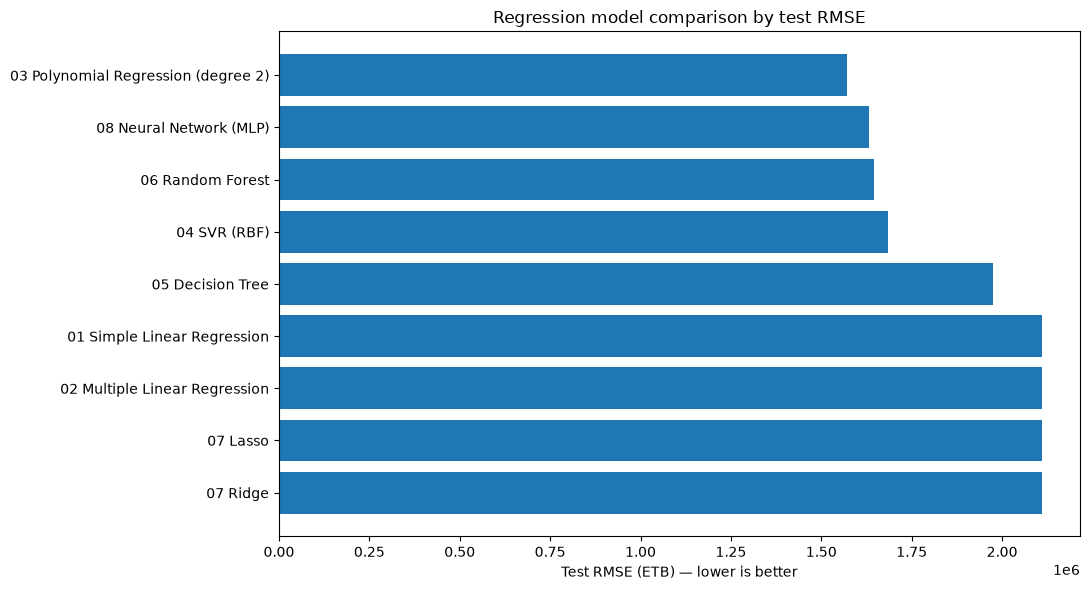

In [7]:
ranking = comparison[["Model", "Test_MAE", "Test_RMSE", "Test_R2", "Train_RMSE"]].copy()
ranking.insert(0, "Rank_by_Test_RMSE", np.arange(1, len(ranking) + 1))
display(ranking.round(4))

plt.figure(figsize=(11, 6))
plot_data = comparison.sort_values("Test_RMSE", ascending=True)
plt.barh(plot_data["Model"], plot_data["Test_RMSE"])
plt.gca().invert_yaxis()
plt.xlabel("Test RMSE (ETB) — lower is better")
plt.title("Regression model comparison by test RMSE")
plt.tight_layout()
plt.show()

## 8. Compare previously saved notebook metrics (optional)

This section looks for metric CSV files from notebooks 01–08. Those results are only directly comparable if the earlier notebooks used the same rows, features, and split. The standardized suite above is the safer comparison when prior setups differ.

In [8]:
metrics_dir = Path("outputs") / "metrics"
candidate_files = [
    metrics_dir / "01_slr_metrics.csv",
    metrics_dir / "02_mlr_metrics.csv",
    metrics_dir / "03_polynomial_regression_metrics.csv",
    metrics_dir / "04_svr_metrics.csv",
    metrics_dir / "05_decision_tree_metrics.csv",
    metrics_dir / "06_random_forest_metrics.csv",
    metrics_dir / "07_ridge_final_metrics.csv",
    metrics_dir / "08_neural_network_final_metrics.csv",
]
available = [p for p in candidate_files if p.exists()]
if available:
    print("Found saved metric files:")
    for path in available:
        print("-", path)
    print("Inspect them individually. Their column layouts may differ between notebooks.")
else:
    print("No known saved metric CSV files found at", metrics_dir.resolve())
    print("This is okay: the comparison suite above computes a consistent set of metrics.")

Found saved metric files:
- outputs\metrics\01_slr_metrics.csv
- outputs\metrics\07_ridge_final_metrics.csv
- outputs\metrics\08_neural_network_final_metrics.csv
Inspect them individually. Their column layouts may differ between notebooks.


## 9. Interpretation guide

Use the actual ranking table to write your conclusions:

1. **Best predictive accuracy:** identify the lowest test RMSE and check whether its test MAE is also competitive.
2. **Generalization:** compare train RMSE with test RMSE. A much lower train error can indicate overfitting.
3. **Explained variation:** compare test R²; a negative value means worse performance than predicting the test-set mean.
4. **Complexity and practicality:** consider runtime, stability, and explainability—not just score.
5. **Leakage and validity:** verify every feature would be available when a real prediction is made.
6. **No universal winner:** model rankings depend on data, features, split, preprocessing, and tuning.

Do not write that one algorithm is best until you have examined your actual results.

## 10. Save comparison outputs

In [9]:
output_dir = Path("outputs") / "metrics"
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(output_dir / "09_model_comparison_metrics.csv", index=False)
ranking.to_csv(output_dir / "09_model_comparison_ranking.csv", index=False)

print("Saved comparison files to:", output_dir.resolve())

Saved comparison files to: C:\Users\hp\ML_Course\Notebooks\Regression\outputs\metrics


## 11. Final assignment report template

After running the notebook, fill in this short report using your actual values:

- **Dataset and target:** [describe dataset and `price_etb`]
- **Split and fairness:** [80/20, random state, common features]
- **Best model by test RMSE:** [model name and RMSE]
- **Best/competitive model by test MAE:** [model name and MAE]
- **Test R² interpretation:** [value and meaning]
- **Overfitting observation:** [train vs test comparison]
- **Limitations:** [leakage, omitted features, data quality, generalization]
- **Conclusion:** [which model you would choose and why]

### Understanding check
1. Why must models use the same test rows for a fair comparison?
2. Why should hyperparameter tuning avoid the test set?
3. Why might the model with the lowest RMSE not be the best practical choice?
4. What is the difference between a good score and a trustworthy experiment?